# Advanced Factorization Models

Pada sistem rekomendasi dan prediksi klik iklan (*CTR Prediction*), data biasanya berbentuk matriks yang sangat jarang (*sparse*). Model regresi biasa gagal menangkap interaksi antar fitur pada data seperti ini. Dua algoritma paling populer untuk mengatasi masalah ini adalah **Factorization Machines (FM)** dan **Field-aware Factorization Machines (FFM)**.

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')

# Mengatur seed acak agar inisialisasi vektor laten (v) selalu konsisten setiap kode dijalankan
np.random.seed(42)

# Membuat tabel (DataFrame) berisi histori interaksi user memberikan rating ke film
df = pd.DataFrame({
  'user': ['User_1', 'User_1', 'User_1', 'User_2', 'User_2', 'User_3', 'User_3'],
  'movie': ['Movie_A', 'Movie_B', 'Movie_C', 'Movie_A', 'Movie_B', 'Movie_B', 'Movie_C'],
  'rating': [5.0, 3.0, 1.0, 4.5, 2.5, 4.0, 5.0],
})

print('=== Dataset Awal ===')
display(df)

# Mengubah kolom kategorikal ('user' dan 'movie') menjadi kolom fitur biner (1.0 jika aktif, 0.0 jika tidak)
dfEncoded = pd.get_dummies(df[['user', 'movie']], dtype=float)
print('=== Dataset Hasil One-Hot Encoding ===')
display(dfEncoded)

# Mengubah DataFrame fitur (X) dan kolom target rating (y) menjadi array NumPy untuk pelatihan model
xTrain = dfEncoded.to_numpy()
yTrain = df['rating'].to_numpy()

# Mengambil jumlah total fitur (n) dari jumlah kolom pada xTrain (dalam kasus ini 6 fitur)
numFeatures = xTrain.shape[1] 

# Membuat skenario kombinasi user dan film baru yang belum pernah ada di data latih
dfNew = pd.DataFrame({
  'user': ['User_2', 'User_3'],
  'movie': ['Movie_C', 'Movie_A'],
})

# Melakukan One-Hot Encoding pada data baru, lalu menyamakan urutan & jumlah kolomnya dengan data latih
# Kolom fitur yang tidak muncul pada dfNew otomatis diisi dengan nilai 0
dfNewEncoded = pd.get_dummies(dfNew, dtype=float).reindex(columns=dfEncoded.columns, fill_value=0)

# Mengubah data baru yang sudah di-encode menjadi array NumPy
xNew = dfNewEncoded.to_numpy()

=== Dataset Awal ===


,user,movie,rating
0,User_1,Movie_A,5.0
1,User_1,Movie_B,3.0
2,User_1,Movie_C,1.0
3,User_2,Movie_A,4.5
4,User_2,Movie_B,2.5
5,User_3,Movie_B,4.0
6,User_3,Movie_C,5.0


=== Dataset Hasil One-Hot Encoding ===


,user_User_1,user_User_2,user_User_3,movie_Movie_A,movie_Movie_B,movie_Movie_C
0,1.0,0.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,1.0,0.0
5,0.0,0.0,1.0,0.0,1.0,0.0
6,0.0,0.0,1.0,0.0,0.0,1.0


## Factorization Machines (FM) dengan Stochastic Gradient Descent (SGD)

**Factorization Machines (FM)** adalah algoritma *supervised learning* yang menggabungkan keunggulan **Regresi Linear** dan **Matrix Factorization**. Model ini dirancang khusus untuk menangkap interaksi antar-fitur secara efisien pada data yang sangat jarang (*sparse*), seperti matriks interaksi pengguna dan film (*user-item*) pada sistem rekomendasi.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model FM orde-2 memprediksi nilai target $\hat{y}(\mathbf{x})$ menggunakan persamaan berikut:

$$\hat{y}(\mathbf{x}) = \underbrace{w_0 + \sum_{i=1}^{n} w_i x_i}_{\text{Bagian Linear}} + \underbrace{\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j}_{\text{Bagian Interaksi Berpasangan}}$$

Berikut adalah pemetaan antara simbol matematis dengan atribut di dalam `class FactorizationMachine`:

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $n$ | `self.numFeatures` | Jumlah total fitur pada vektor input $\mathbf{x}$. |
| $k$ | `self.latentDim` | Dimensi vektor laten (jumlah faktor tersembunyi untuk tiap fitur). |
| $\eta$ (*eta*) | `self.learningRate` | Laju pembelajaran yang mengatur besar langkah pembaruan bobot SGD. |
| $\lambda$ (*lambda*) | `self.regParam` | Parameter penalti regularisasi L2 untuk mencegah *overfitting*. |
| $w_0$ | `self.w0` | **Bias global** (skalar), nilai dasar prediksi saat semua fitur bernilai nol. |
| $\mathbf{w}$ ($w_i$) | `self.w` | **Vektor bobot linear** berukuran $(n,)$, mengukur pengaruh individu fitur ke-$i$. |
| $\mathbf{V}$ ($\mathbf{v}_i$) | `self.v` | **Matriks vektor laten** berukuran $(n \times k)$, merepresentasikan karakteristik fitur ke-$i$. |
| $\langle \mathbf{v}_i, \mathbf{v}_j \rangle$ | Dot product baris `self.v` | Perkalian titik antar dua vektor laten: $\sum_{f=1}^{k} v_{i,f} \cdot v_{j,f}$. |

---

## 2. Cara Kerja Metode `predict(self, x, clip)`

Menghitung interaksi berpasangan $\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j$ secara langsung membutuhkan *nested loop* dengan kompleksitas waktu $\mathcal{O}(kn^2)$. Menggunakan identitas aljabar $(a + b)^2 = a^2 + b^2 + 2ab$, persamaan tersebut disederhanakan menjadi $\mathcal{O}(kn)$:

$$\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j = \frac{1}{2} \sum_{f=1}^{k} \left[ \underbrace{\left(\sum_{i=1}^{n} v_{i,f} x_i\right)^2}_{\texttt{sumSquare}} - \underbrace{\sum_{i=1}^{n} v_{i,f}^2 x_i^2}_{\texttt{squareSum}} \right]$$

Alur komputasi di dalam `predict(x)`:
1. **`linearPart`:** Menghitung $w_0 + \mathbf{w} \cdot \mathbf{x}$ menggunakan `self.w0 + np.dot(self.w, x)`.
2. **`sumSquare`:** Menjumlahkan perkalian fitur dan faktor laten lalu mengkuadratkannya (`np.sum(np.dot(x, self.v)**2)`).
3. **`squareSum`:** Menghitung interaksi fitur dengan dirinya sendiri (`np.sum(np.dot(x**2, self.v**2))`).
4. **`interactionPart`:** Mengurangkan `squareSum` dari `sumSquare` lalu dikali `0.5` agar pasangan $(i, j)$ dan $(j, i)$ tidak terhitung dua kali.
5. **`np.clip`:** Saat evaluasi atau inference membatasi hasil prediksi mentah (`rawPred`) agar selalu berada dalam rentang skala rating yang valid (`1.0` hingga `5.0`).

---

## 3. Proses Pelatihan di Metode `fit(self, xTrain, yTrain, epochs)`

Metode `fit` bertugas melatih model agar tebakannya semakin akurat dari waktu ke waktu. Proses ini bekerja seperti latihan soal: model menebak jawaban untuk satu baris data, memeriksa seberapa jauh tebakannya meleset, lalu memperbaiki parameter internalnya sedikit demi sedikit (*Stochastic Gradient Descent* / SGD).

### Tujuan Pelatihan (Fungsi *Loss*)
Model berusaha membuat nilai kesalahan (*Loss*, $\mathcal{L}$) sekecil mungkin berdasarkan dua aturan:

$$\mathcal{L} = \underbrace{\frac{1}{2} \left(\hat{y}(\mathbf{x}) - y\right)^2}_{\text{1. Error Tebakan (MSE)}} + \underbrace{\frac{\lambda}{2} \left( w_0^2 + \|\mathbf{w}\|^2 + \|\mathbf{V}\|_F^2 \right)}_{\text{2. Hukuman Regularisasi L2}}$$

* **Error Tebakan (MSE):** Mengukur selisih antara tebakan model ($\hat{y}$) dan jawaban asli ($y$). Semakin besar melesetnya, semakin besar nilainya.
* **Regularisasi L2 ($\lambda$):** Berfungsi sebagai "rem" agar nilai parameter tidak membengkak terlalu besar. Ini mencegah model sekadar menghafal data latih (*overfitting*).

---

### Langkah Pembaruan Parameter (Per Satu Baris Data)
Setiap kali membaca satu baris data `x` dan label aslinya `y`, model menjalankan 5 langkah berikut secara berurutan:

1. **Hitung Selisih Tebakan (`error`):**
   $$e = \hat{y}(\mathbf{x}) - y$$
   Model menghitung seberapa meleset tebakannya. Jika $e$ positif, tebakan terlalu tinggi; jika negatif, tebakan terlalu rendah.

2. **Koreksi Nilai Dasar (`self.w0`):**
   $$w_0 \leftarrow w_0 - \eta \cdot (e + \lambda w_0)$$
   Bias global ($w_0$) adalah titik awal tebakan sebelum melihat fitur apa pun. Jika tebakan terlalu tinggi, nilai $w_0$ diturunkan sedikit sebesar kecepatan belajar ($\eta$ / *learning rate*).

3. **Pilih Fitur yang Aktif Saja (`activeIndices`):**
   Model mencari kolom fitur yang nilainya tidak nol ($x_i > 0$) menggunakan `np.where(x > 0)[0]`. Fitur yang bernilai $0$ diabaikan karena tidak memengaruhi hasil perkalian, sehingga komputasi pada data besar (*sparse*) menjadi sangat cepat.

4. **Koreksi Bobot Fitur Tunggal (`self.w[i]`):**
   $$w_i \leftarrow w_i - \eta \cdot (e \cdot x_i + \lambda w_i)$$
   Untuk setiap fitur yang aktif, bobotnya ($w_i$) disesuaikan. Semakin besar nilai input $x_i$, semakin besar tanggung jawab fitur tersebut atas kesalahan tebakan ($e$).

5. **Koreksi Vektor Interaksi (`self.v[i]`):**
   $$\mathbf{v}_i \leftarrow \mathbf{v}_i - \eta \cdot (\text{gradV} + \lambda \mathbf{v}_i)$$
   Vektor laten ($\mathbf{v}_i$) merepresentasikan kecocokan antara fitur ke-$i$ dengan fitur lainnya. Untuk memperbaruinya, model menghitung `gradV = error * x[i] * (sumVx - self.v[i] * x[i])`:
   * **`sumVx`** adalah total vektor dari **semua** fitur yang sedang aktif.
   * **`sumVx - self.v[i] * x[i]`** membuang pengaruh fitur ke-$i$ itu sendiri dari total tersebut. Hasilnya adalah pengaruh murni dari **fitur-fitur lain** ($j \neq i$) yang berpasangan dengannya.


---

## 4. Contoh Hitungan Sederhana

Misalkan kita ingin memprediksi rating **User 1** untuk **Movie A** dengan $n = 2$ fitur aktif (`x = [1, 1]`) dan dimensi laten $k = 2$:
* **Parameter terlatih:**
  * Bias global: $w_0 = 3.0$
  * Bobot linear: $\mathbf{w} = [0.5, 0.4]$
  * Vektor laten: $\mathbf{v}_{\text{User 1}} = [0.8, 0.2]$ dan $\mathbf{v}_{\text{Movie A}} = [0.9, 0.5]$

**Langkah Perhitungan:**

$$\hat{y}(\mathbf{x}) = \underbrace{w_0 + \sum_{i=1}^{n} w_i x_i}_{\text{Bagian Linear}} + \underbrace{\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j}_{\text{Bagian Interaksi Berpasangan}}$$

$$\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j = \frac{1}{2} \sum_{f=1}^{k} \left[ \underbrace{\left(\sum_{i=1}^{n} v_{i,f} x_i\right)^2}_{\texttt{sumSquare}} - \underbrace{\sum_{i=1}^{n} v_{i,f}^2 x_i^2}_{\texttt{squareSum}} \right]$$

1. **`linearPart`:**
   $$3.0 + (0.5 \times 1) + (0.4 \times 1) = 3.9$$
2. **`interactionPart`:**
   * `sumSquare`: $(0.8 + 0.9)^2 + (0.2 + 0.5)^2 = 1.7^2 + 0.7^2 = 2.89 + 0.49 = 3.38$
   * `squareSum`: $(0.8^2 + 0.9^2) + (0.2^2 + 0.5^2) = (0.64 + 0.81) + (0.04 + 0.25) = 1.74$
   * Hasil interaksi: $0.5 \times (3.38 - 1.74) = 0.82$
3. **Prediksi Akhir (`np.clip`):**
   $$\text{rawPred} = 3.9 + 0.82 = 4.72 \rightarrow \text{clip}(4.72, 1.0, 5.0) = \mathbf{4.72}$$

---

## 5. Aplikasi Factorization Machines (FM)

Factorization Machines (FM) dapat digunakan pada berbagai sistem rekomendasi dan prediksi yang memanfaatkan interaksi antar-fitur, terutama pada dataset dengan karakteristik *sparse*:

1. **Rekomendasi Film:** Memperkirakan rating pengguna terhadap film berdasarkan interaksi pengguna–film. Pada konfigurasi MovieLens ini, model memprediksi rating dalam rentang **1–5** menggunakan kombinasi bobot linear dan faktor laten.
2. **Rekomendasi Produk E-Commerce:** Memprediksi preferensi pengguna terhadap produk berdasarkan interaksi antara pengguna, produk, kategori, dan atribut lainnya.
3. **Rekomendasi Konten Digital:** Memperkirakan ketertarikan pengguna terhadap musik, video, atau artikel dengan mempelajari interaksi antara pengguna, konten, dan fitur kontekstual.
4. **Prediksi Klik Iklan (*Click-Through Rate*):** Memperkirakan kemungkinan pengguna mengklik iklan berdasarkan interaksi antara profil pengguna, karakteristik iklan, dan konteks penayangan.

---

## 6. Kelebihan dan Kekurangan Factorization Machines

| Kelebihan (*Pros*) | Kekurangan (*Cons*) |
| :--- | :--- |
| **Sangat Efisien pada Data Sparse:** Mampu mempelajari interaksi fitur meskipun dua fitur belum pernah muncul bersamaan di data latih (berkat vektor laten $\mathbf{v}_i$). | **Hanya Menangkap Interaksi Orde-2:** Secara standar hanya memodelkan interaksi berpasangan ($x_i x_j$), kurang optimal untuk pola non-linear tingkat tinggi seperti *Deep Neural Networks*. |
| **Kompleksitas Waktu Linear $\mathcal{O}(kn)$:** Trik aljabar membuat proses prediksi dan pelatihan jauh lebih cepat dibanding regresi polinomial standar $\mathcal{O}(n^2)$. | **Sensitif terhadap Hiperparameter:** Performa sangat bergantung pada pemilihan `learningRate` ($\eta$), `regParam` ($\lambda$), dan `latentDim` ($k$). |
| **Fleksibel untuk Berbagai Fitur:** Tidak terbatas pada *user-item* saja; dapat menggabungkan fitur kategorikal (*one-hot*) dan fitur numerik (umur, waktu, harga) secara bersamaan. | **Rentan Overfitting pada Dataset Kecil:** Jika jumlah data latih terlalu sedikit dibanding ukuran matriks $\mathbf{V}$, model mudah menghafal data tanpa regularisasi yang kuat. |


In [8]:
class FactorizationMachine:
  """
    Implementasi model Factorization Machines (FM) dengan optimasi Stochastic Gradient Descent (SGD).
    
    Persamaan Model:
    y_hat(x) = w0 + sum_{i=1..n}(w_i * x_i) + sum_{i=1..n} sum_{j=i+1..n} (<v_i, v_j> * x_i * x_j)
  """
  
  def __init__(self, numFeatures, latentDim=3, learningRate=0.015, regParam=0.01):
    """
    Inisialisasi hiperparameter dan parameter model Factorization Machines.

    Args:
      numFeatures (int): Merepresentasikan simbol n, yaitu jumlah total fitur pada satu baris data input x.
      latentDim (int, optional): Merepresentasikan simbol k, yaitu panjang dimensi vektor laten v_i untuk setiap fitur. Default 3.
      learningRate (float, optional): Merepresentasikan simbol eta, yaitu laju pembelajaran untuk mengontrol besar langkah pembaruan bobot. Default 0.015.
      regParam (float, optional): Merepresentasikan simbol lambda, yaitu parameter penalti regularisasi L2 untuk mencegah overfitting. Default 0.01.
    """
    
    # n: Jumlah total fitur pada vektor input x
    self.numFeatures = numFeatures
    
    # k: Dimensi vektor laten v_i
    self.latentDim = latentDim
    
    # eta: Laju pembelajaran untuk pembaruan parameter SGD
    self.learningRate = learningRate
    
    # lambda: Parameter regularisasi L2 untuk mencegah overfitting
    self.regParam = regParam
    
    # Inisialisasi parameter yang akan dipelajari model:
    # w0 : Bias global (nilai rata-rata dasar prediksi)
    self.w0 = 0.0
    
    # w: Vektor bobot linear w_i untuk setiap fitur ke-i (berukuran n)
    self.w = np.zeros(numFeatures)
    
    # v: Matriks vektor laten v_i berukuran (n x k) untuk merepresentasikan karakteristik tiap fitur
    self.v = np.random.normal(0, 0.1, (numFeatures, latentDim))
    
    self.lossHistory = []
  
  def fit(self, xTrain, yTrain, epochs=50):
    """
      Melatih parameter model (w0, w_i, dan v_i) menggunakan Stochastic Gradient Descent (SGD).
      Tujuannya adalah meminimalkan error prediksi (MSE) ditambah penalti regularisasi L2.

      Args:
        xTrain (np.ndarray): Matriks data latih berukuran (jumlah_sampel, numFeatures), tiap baris adalah x.
        yTrain (np.ndarray): Vektor target/label aktual y berukuran (jumlah_sampel,).
        epochs (int, optional): Berapa kali model membaca seluruh dataset dari awal sampai akhir. Default 50.
    """
    
    # Mengambil jumlah baris sampel (N) dari matriks data latih
    numSamples = xTrain.shape[0]
    
    # Ulangi proses pembelajaran sebanyak 'epochs' kali
    for epoch in range(epochs):
      # Menyimpan total kuadrat error untuk 1 epoch penuh
      epochsLoss = 0.0
      
      # Loop setiap satu baris data (ini adalah ciri khas SGD: update bobot per 1 baris sampel)
      for idx in range(numSamples):
        # Ambil satu baris fitur input (x) dan nilai jawaban aslinya (y)
        x = xTrain[idx]
        y = yTrain[idx]
        
        # 1. HITUNG PREDIKSI & ERROR
        # Hitung tebakan model saat ini: y_hat(x)
        yPred = self.predict(x, False)
        
        # Hitung selisih tebakan dengan jawaban asli: error = y_hat(x) - y
        # Jika error > 0, tebakan terlalu tinggi. Jika error < 0, tebakan terlalu rendah.
        error = yPred - y
        
        # 2. UPDATE BIAS GLOBAL (w0)
        # Rumus: w0 = w0 - eta * (error + lambda * w0)
        # error              : menggeser w0 ke arah yang mengurangi error
        # self.regParam * w0 : regularisasi L2 (menahan nilai w0 agar tidak membengkak)
        self.w0 -= self.learningRate * (error + self.regParam * self.w0)
        
        # 3. CARI FITUR YANG AKTIF SAJA
        # Fitur yang nilainya 0 (x_i == 0) tidak berpengaruh pada hasil perkalian,
        # jadi kita hanya ambil indeks fitur yang x_i != 0 agar komputasi jauh lebih cepat.
        activeIndices = np.where(x != 0)[0]
        
        # Hitung total perkalian seluruh fitur aktif dengan vektor latennya: sum_{j=1..n} (v_j * x_j)
        sumVx = np.dot(x[activeIndices], self.v[activeIndices])
        
        # 4. UPDATE BOBOT LINEAR (w_i) DAN VEKTOR LATEN (v_i) UNTUK TIAP FITUR AKTIF
        for i in activeIndices:
          # Update bobot linear w_i:
          # Rumus: w_i = w_i - eta * (error * x_i + lambda * w_i)
          # Semakin besar nilai input x_i, semakin besar tanggung jawab w_i terhadap error.
          self.w[i] -= self.learningRate * (error * x[i] + self.regParam * self.w[i])
          
          # Hitung gradien (arah perubahan) untuk vektor laten v_i:
          # Rumus turunan: error * x_i * (sumVx - v_i * x_i)
          # Bagian (sumVx - v_i * x_i) adalah jumlah pengaruh semua fitur LAIN selain fitur ke-i sendiri,
          # karena fitur ke-i hanya berinteraksi dengan fitur j != i.
          gradV = error * x[i] * (sumVx - self.v[i] * x[i])
          
          # Update vektor laten v_i menggunakan gradien di atas + regularisasi L2:
          # Rumus: v_i = v_i - eta * (gradV + lambda * v_i)
          self.v[i] -= self.learningRate * (gradV + self.regParam * self.v[i])
      
      # 5. HITUNG TOTAL REGULARIZED LOSS SETELAH SATU EPOCH
      # Hitung ulang prediksi menggunakan parameter model terbaru
      predictions = np.array([
        self.predict(x, False)
        for x in xTrain
      ])
      
      # Hitung rata-rata kuadrat error (MSE) dengan faktor 1/2
      # Rumus: 0.5 * mean((y_hat - y) ^ 2)
      predLoss = 0.5 * np.mean((predictions - yTrain)**2)
      
      # Hitung penalti regularisasi L2 untuk seluruh parameter model
      # Rumus: 0.5 * lambda * (w0^2 + ||w||^2 + ||V||_F^2)
      regLoss = 0.5 * self.regParam * (
        self.w0**2 + np.sum(self.w**2) + np.sum(self.v**2)
      )
      
      # Simpan total loss (prediction error + regularisasi L2) ke riwayat training
      self.lossHistory.append(predLoss + regLoss)
    
  def predict(self, x, clip=True):
    """
      Menghitung nilai hasil prediksi model y_hat(x) untuk satu sampel data input.

      Args:
        x (np.ndarray): Merepresentasikan vektor input x = [x_1, x_2, ..., x_n] berukuran (numFeatures,) yang berisi nilai input dari setiap fitur ke-i.
        clip (bool, optional): Menentukan apakah nilai prediksi dibatasi pada rentang rating 1.0 hingga 5.0. True untuk membatasi prediksi saat evaluasi atau inference, False untuk menggunakan prediksi mentah saat training. Default True.

      Returns:
        float: Nilai hasil prediksi model y_hat(x).
    """
    
    # 1. BAGIAN LINEAR
    # Rumus: w_0 + sum(w_i * x_i)
    # - self.w0             ---> simbol w_0 (bias global / nilai dasar)
    # - self.w              ---> simbol vektor bobot [w_1, w_2, ..., w_n]
    # - np.dot(w, x)        ---> simbol sum(w_i * x_i)
    linearPart = self.w0 + np.dot(self.w, x)
    
    # 2. Bagian Interaksi: sum_i sum_{j>i} (<v_i, v_j> * x_i * x_j)
    # Trik aljabar: (a + b)^2 = a^2 + b^2 + 2ab  -->  ab = 0.5 * ((a + b)^2 - (a^2 + b^2))
    # Mengubah kompleksitas waktu dari O(k * n^2) menjadi O(k * n) tanpa nested loop.
    
    # sumSquare ---> merepresentasikan: sum_f ( (sum_i v_{i,f} * x_i)^2 )
    # Langkah A: np.dot(x, self.v) menghitung (sum_i v_{i,f} * x_i) untuk setiap faktor f
    # Langkah B: **2 mengkuadratkan setiap hasil penjumlahan tersebut
    # Langkah C: np.sum(...) menjumlahkan seluruh k faktor laten menjadi satu angka
    sumSquare = np.sum(np.dot(x, self.v)**2)
    
    # squareSum ---> merepresentasikan: sum_f sum_i ( v_{i,f}^2 * x_i^2 )
    # Langkah A: x**2 menghitung x_i^2, dan self.v**2 menghitung v_{i,f}^2
    # Langkah B: np.dot(...) mengalikan lalu menjumlahkannya untuk semua fitur i
    # Langkah C: np.sum(...) menjumlahkan seluruh k faktor laten menjadi satu angka
    squareSum = np.sum(np.dot(x**2, self.v**2))
    
    # interactionPart ---> merepresentasikan keseluruhan bagian interaksi:
    # 0.5 * (sumSquare - squareSum) nilainya sama persis dengan sum_i sum_{j>i} (<v_i, v_j> * x_i * x_j)
    interactionPart = 0.5 * (sumSquare - squareSum)
    
    # 3. HASIL PREDIKSI AKHIR
    # Rumus: y_hat(x) = linearPart + interactionPart
    rawPred = linearPart + interactionPart
    
    if not clip: return rawPred
    
    # np.clip memotong nilai prediksi yang keluar dari batas wajar skala rating
    return np.clip(rawPred, min=1.0, max=5.0)

In [9]:
# Membuat objek model FM dengan dimensi laten k=2, laju pembelajaran eta=0.05, dan regularisasi lambda=0.01
fm = FactorizationMachine(numFeatures=numFeatures, latentDim=2, learningRate=0.05, regParam=0.01)

# Melatih parameter model (w0, w, dan v) selama 200 putaran penuh (epochs)
fm.fit(xTrain, yTrain, epochs=200)

# Melakukan prediksi rating satu per satu untuk setiap baris sampel baru pada xNew
yPredsFM: list[float] = [fm.predict(x) for x in xNew]

dfNew['predictedRatingFM'] = yPredsFM

##

## Field-aware Factorization Machines (FFM) dengan Stochastic Gradient Descent (SGD)

**Field-aware Factorization Machines (FFM)** adalah pengembangan lanjutan dari *Factorization Machines* (FM) yang dirancang khusus untuk data dengan fitur kategorikal multi-kelompok (*multi-field*). Alih-alih menggunakan satu vektor laten tunggal untuk setiap fitur, FFM mengelompokkan fitur ke dalam kategori induk bernama **Field** (misalnya: *User*, *Movie*, *Device*). Dengan pendekatan ini, sebuah fitur memiliki vektor laten yang berbeda-beda tergantung pada *field* dari fitur lawannya.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model FFM memprediksi nilai target $\hat{y}(\mathbf{x})$ menggunakan persamaan berikut:

$$\hat{y}(\mathbf{x}) = \underbrace{w_0 + \sum_{i=1}^{n} w_i x_i}_{\text{Bagian Linear}} + \underbrace{\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_{i, f_j}, \mathbf{v}_{j, f_i} \rangle x_i x_j}_{\text{Bagian Interaksi Spesifik Field}}$$

Berikut adalah pemetaan antara simbol matematis dengan atribut di dalam `class FieldAwareFactorizationMachine`:

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $n$ | `self.numFeatures` | Jumlah total fitur pada vektor input $\mathbf{x}$. |
| $F$ | `self.numFields` | Jumlah total kategori induk (*field*) yang mengelompokkan fitur. |
| $f_i$ | `self.fieldMap` | Pemetaan indeks fitur ke-$i$ menuju indeks kategori induk (*field*)-nya. |
| $k$ | `self.latentDim` | Dimensi vektor laten (jumlah faktor tersembunyi untuk tiap interaksi *field*). |
| $\eta$ (*eta*) | `self.learningRate` | Laju pembelajaran yang mengatur besar langkah pembaruan bobot SGD. |
| $\lambda$ (*lambda*) | `self.regParam` | Parameter penalti regularisasi L2 untuk mencegah *overfitting*. |
| $w_0$ | `self.w0` | **Bias global** (skalar), nilai dasar prediksi saat semua fitur bernilai nol. |
| $\mathbf{w}$ ($w_i$) | `self.w` | **Vektor bobot linear** berukuran $(n,)$, mengukur pengaruh individu fitur ke-$i$. |
| $\mathbf{V}$ ($\mathbf{v}_{i, f_j}$) | `self.v` | **Tensor vektor laten 3D** berukuran $(n \times F \times k)$, merepresentasikan karakteristik fitur ke-$i$ saat berinteraksi dengan *field* $f_j$. |
| $\langle \mathbf{v}_{i, f_j}, \mathbf{v}_{j, f_i} \rangle$ | `np.dot(self.v[i, fieldJ], self.v[j, fieldI])` | Perkalian titik antar dua vektor laten spesifik *field* lawan. |

---

## 2. Cara Kerja Metode `predict(self, x, clip)`

Karena setiap pasangan fitur $(i, j)$ menggunakan vektor laten yang bergantung pada *field* lawannya ($f_j$ dan $f_i$), FFM tidak dapat disederhanakan menjadi $\mathcal{O}(kn)$ seperti FM standar. Komputasi dilakukan dengan mengiterasi pasangan fitur yang aktif saja ($x_i > 0$) dengan kompleksitas $\mathcal{O}(k m^2)$, di mana $m$ adalah jumlah fitur aktif (*non-zero*):

$$\text{interactionPart} = \sum_{i \in \text{aktif}} \sum_{\substack{j \in \text{aktif} \\ j > i}} \langle \mathbf{v}_{i, f_j}, \mathbf{v}_{j, f_i} \rangle x_i x_j$$

Alur komputasi di dalam `predict(x)`:
1. **`linearPart`:** Menghitung $w_0 + \mathbf{w} \cdot \mathbf{x}$ menggunakan `self.w0 + np.dot(self.w, x)`.
2. **`activeIndices`:** Mengambil indeks kolom yang bernilai tidak nol (`np.where(x > 0)[0]`) agar komputasi data *sparse* tetap cepat.
3. **Nested Loop Pasangan Aktif (`idxA`, `idxB`):** Memasangkan setiap dua fitur aktif $(i, j)$ dengan syarat $j > i$ agar tidak ada pasangan yang dihitung dua kali.
4. **`fieldI` & `fieldJ`:** Mencari kategori induk masing-masing fitur menggunakan `self.fieldMap[i]` dan `self.fieldMap[j]`.
5. **`dotProduct`:** Mengambil vektor fitur $i$ untuk *field* $j$ (`self.v[i, fieldJ]`) dan vektor fitur $j$ untuk *field* $i$ (`self.v[j, fieldI]`), lalu menghitung perkalian titiknya menggunakan `np.dot(...)`.
6. **`interactionPart`:** Mengalikan hasil `dotProduct` dengan nilai fitur $x_i$ dan $x_j$, lalu menjumlahkannya ke total interaksi.
7. **`np.clip`:** Saat evaluasi atau inference membatasi hasil prediksi mentah (`rawPred`) agar selalu berada dalam rentang skala rating yang valid (`1.0` hingga `5.0`).

---

## 3. Proses Pelatihan di Metode `fit(self, xTrain, yTrain, epochs)`

Metode `fit` melatih parameter model agar selisih antara tebakan ($\hat{y}$) dan jawaban asli ($y$) semakin kecil menggunakan *Stochastic Gradient Descent* (SGD).

### Tujuan Pelatihan (Fungsi *Loss*)
Model meminimalkan fungsi *loss* ($\mathcal{L}$) yang menggabungkan kesalahan prediksi kuadrat dan penalti regularisasi L2 pada seluruh parameter:

$$\mathcal{L} = \underbrace{\frac{1}{2} \left(\hat{y}(\mathbf{x}) - y\right)^2}_{\text{1. Error Tebakan (MSE)}} + \underbrace{\frac{\lambda}{2} \left( w_0^2 + \|\mathbf{w}\|^2 + \|\mathbf{V}\|_F^2 \right)}_{\text{2. Hukuman Regularisasi L2}}$$

* **Error Tebakan (MSE):** Mengukur seberapa jauh prediksi model ($\hat{y}$) meleset dari label sebenarnya ($y$).
* **Regularisasi L2 ($\lambda$):** Menahan nilai bobot dan tensor $\mathbf{V}$ agar tidak tumbuh terlalu besar, karena FFM memiliki jumlah parameter jauh lebih banyak dibanding FM.

---

### Langkah Pembaruan Parameter (Per Satu Baris Data)
Setiap kali membaca satu baris sampel `x` dan target `y`, model menjalankan 6 langkah pembaruan berikut:

1. **Hitung Selisih Tebakan (`error`):**
   $$e = \hat{y}(\mathbf{x}) - y$$
   Menghitung selisih tebakan model saat ini dengan nilai asli. Nilai positif berarti tebakan terlalu tinggi; negatif berarti terlalu rendah.

2. **Koreksi Nilai Dasar (`self.w0`):**
   $$w_0 \leftarrow w_0 - \eta \cdot (e + \lambda w_0)$$
   Memperbarui bias global ($w_0$) berlawanan arah dengan gradien *error* ditambah penalti regularisasi.

3. **Cari Fitur yang Aktif (`activeIndices`):**
   Mengambil indeks fitur dengan $x_i \neq 0$ menggunakan `np.where(x != 0)`. Fitur bernilai $0$ dilewati untuk menghemat waktu komputasi.

4. **Koreksi Bobot Fitur Tunggal (`self.w[i]`):**
   $$w_i \leftarrow w_i - \eta \cdot (e \cdot x_i + \lambda w_i)$$
   Menyesuaikan bobot linear ($w_i$) untuk setiap fitur aktif sesuai kontribusinya terhadap *error*.

5. **Akumulasi Gradien & Koreksi Tensor Vektor Laten (`self.v`):**
   $$\mathbf{v}_{i, f_j} \leftarrow \mathbf{v}_{i, f_j} - \eta \cdot (e \cdot x_i x_j \mathbf{v}_{j, f_i} + \lambda \mathbf{v}_{i, f_j})$$
   $$\mathbf{v}_{j, f_i} \leftarrow \mathbf{v}_{j, f_i} - \eta \cdot (e \cdot x_i x_j \mathbf{v}_{i, f_j} + \lambda \mathbf{v}_{j, f_i})$$
   * **Abaikan Field yang Sama:** Jika dua fitur berasal dari *field* yang sama (`fieldI == fieldJ`), pasangan tersebut dilewati karena FFM hanya menghitung interaksi antar-*field* yang berbeda.
   * **Penampung Gradien (`gradV`):** Seluruh gradien interaksi ($e \cdot x_i x_j \mathbf{v}$) dikumpulkan terlebih dahulu ke dalam matriks sementara `gradV` agar semua perhitungan memakai parameter lama yang sama.
   * **Pembaruan Serentak:** Setelah semua pasangan dihitung, penalti regularisasi ($\lambda \mathbf{V}$) ditambahkan ke `gradV`, lalu seluruh tensor `self.v` diperbarui sekaligus.

6. **Evaluasi Total Loss di Akhir Epoch (`lossHistory`):**
   Setelah seluruh baris data dalam satu *epoch* selesai diproses, model menghitung ulang prediksi terbaru untuk mencatat nilai total *objective loss* ($\mathcal{L} = \text{predLoss} + \text{regLoss}$).


---

## 4. Contoh Hitungan Sederhana

Misalkan kita memprediksi rating **User 1** untuk **Movie A** dengan $n = 2$ fitur aktif (`x = [1, 1]`), $F = 2$ *field* (`fieldMap = [0, 1]`, di mana `0` = *User* dan `1` = *Movie*), serta dimensi laten $k = 2$:
* **Parameter terlatih:**
  * Bias global: $w_0 = 3.0$
  * Bobot linear: $\mathbf{w} = [0.5, 0.4]$
  * Vektor laten spesifik *field*:
    * $\mathbf{v}_{\text{User 1}, \text{Movie}} = [0.8, 0.3]$ (vektor *User 1* saat berinteraksi dengan *field Movie*)
    * $\mathbf{v}_{\text{Movie A}, \text{User}} = [0.9, 0.4]$ (vektor *Movie A* saat berinteraksi dengan *field User*)

**Langkah Perhitungan:**

$$\hat{y}(\mathbf{x}) = \underbrace{w_0 + \sum_{i=1}^{n} w_i x_i}_{\text{Bagian Linear}} + \underbrace{\sum_{i=1}^{n} \sum_{j=i+1}^{n} \langle \mathbf{v}_{i, f_j}, \mathbf{v}_{j, f_i} \rangle x_i x_j}_{\text{Bagian Interaksi Spesifik Field}}$$

1. **`linearPart`:**
   $$3.0 + (0.5 \times 1) + (0.4 \times 1) = 3.9$$
2. **`interactionPart`:**
   * `dotProduct` ($\langle \mathbf{v}_{0, 1}, \mathbf{v}_{1, 0} \rangle$): $(0.8 \times 0.9) + (0.3 \times 0.4) = 0.72 + 0.12 = 0.84$
   * Hasil interaksi: $0.84 \times 1 \times 1 = 0.84$
3. **Prediksi Akhir (`np.clip`):**
   $$\text{rawPred} = 3.9 + 0.84 = 4.74 \rightarrow \text{clip}(4.74, 1.0, 5.0) = \mathbf{4.74}$$

---

## 5. Aplikasi Field-aware Factorization Machines (FFM)

Field-aware Factorization Machines (FFM) dapat digunakan pada berbagai sistem rekomendasi dan prediksi yang melibatkan interaksi antar-fitur dari kelompok berbeda (*multi-field*), terutama pada dataset dengan karakteristik *sparse*:

1. **Rekomendasi Film:** Memperkirakan rating pengguna terhadap film berdasarkan interaksi pengguna–film. Pada konfigurasi MovieLens ini, model memprediksi rating dalam rentang **1–5** menggunakan kombinasi bobot linear dan vektor laten yang spesifik terhadap *field*.
2. **Rekomendasi Produk E-Commerce:** Memprediksi preferensi pengguna terhadap produk berdasarkan interaksi antara pengguna, produk, kategori, dan atribut lainnya, dengan representasi laten yang berbeda untuk setiap pasangan *field*.
3. **Rekomendasi Konten Digital:** Memperkirakan ketertarikan pengguna terhadap musik, video, atau artikel dengan mempelajari interaksi antara pengguna, konten, dan fitur kontekstual dari berbagai *field*.
4. **Prediksi Klik Iklan (*Click-Through Rate*):** Memperkirakan kemungkinan pengguna mengklik iklan berdasarkan interaksi antara profil pengguna, karakteristik iklan, perangkat, dan konteks penayangan menggunakan vektor laten yang disesuaikan dengan *field* masing-masing.

---

## 6. Kelebihan dan Kekurangan Field-aware Factorization Machines

| Kelebihan (*Pros*) | Kekurangan (*Cons*) |
| :--- | :--- |
| **Akurasi Lebih Tinggi pada Data Multi-Field:** Memisahkan ruang laten antar kategori induk (misal interaksi *User–Movie* berbeda dengan *User–Device*), sehingga menangkap konteks jauh lebih tajam dibanding FM. | **Konsumsi Memori Jauh Lebih Besar:** Ukuran matriks parameter meningkat dari $\mathcal{O}(nk)$ pada FM menjadi $\mathcal{O}(nFk)$, sehingga membutuhkan RAM besar jika jumlah *field* ($F$) banyak. |
| **Standar Emas pada Prediksi CTR & Iklan:** Terbukti unggul dalam berbagai kompetisi sistem rekomendasi dan prediksi klik iklan (*Click-Through Rate*) berskala industri. | **Waktu Komputasi Lebih Lambat:** Tidak memiliki trik penyederhanaan linear $\mathcal{O}(kn)$ seperti FM; kompleksitasnya adalah $\mathcal{O}(k m^2)$ per baris data ($m$ = jumlah fitur aktif). |
| **Representasi Kontekstual yang Fleksibel:** Satu fitur dapat memiliki perilaku yang sangat berbeda ketika dipasangkan dengan *field* yang berbeda tanpa saling mengganggu bobot latennya. | **Sangat Rentan Overfitting:** Karena jumlah parameter meningkat $F$ kali lipat, model mudah menghafal *noise* jika regularisasi L2 ($\lambda$) dan *early stopping* tidak diatur dengan ketat. |


In [10]:
class FieldAwareFactorizationMachines:
  """
    Implementasi model Field-aware Factorization Machines (FFM) dengan optimasi SGD.

    Persamaan Model:
    y_hat(x) = w0 + sum_{i=1..n}(w_i * x_i) + sum_{i=1..n} sum_{j=i+1..n} (<v_{i, f_j}, v_{j, f_i}> * x_i * x_j)
  """
  
  def __init__(self, numFeatures, numFields, fieldMap, latentDim=3, learningRate=0.015, regParam=0.01):
    """
      Inisialisasi parameter, pemetaan field, dan hiperparameter model FFM.

      Args:
        numFeatures (int): Jumlah total fitur input (n).
        numFields (int): Jumlah total kategori induk atau field (F).
        fieldMap (list[int]): Daftar indeks field (f_i) untuk setiap fitur ke-i.
        latentDim (int): Dimensi ruang vektor laten (k).
        learningRate (float): Laju pembelajaran untuk pembaruan gradien (eta).
        regParam (float): Koefisien regularisasi L2 untuk mencegah overfitting (lambda).
    """
    
    # n: jumlah total fitur input
    self.numFeatures = numFeatures
    
    # F: jumlah total kategori induk (field)
    self.numFields = numFields
    
    # f_i: pemetaan indeks fitur ke indeks field
    self.fieldMap = fieldMap
    
    # k: dimensi vektor laten
    self.latentDim = latentDim
    
    # eta: learning rate untuk pembaruan gradien
    self.learningRate = learningRate
    
    # lambda: koefisien regularisasi L2
    self.regParam = regParam
    
    # w0: bias global (skalar)
    self.w0 = 0.0
    
    # w: vektor bobot linear berukuran n
    self.w = np.zeros(numFeatures)
    
    # V: tensor vektor laten 3D berukuran n x F x k
    self.v = np.random.normal(0, 0.1, (numFeatures, numFields, latentDim))
    
    self.lossHistory = []
  
  def fit(self, xTrain, yTrain, epochs=50):
    """
      Melatih parameter model (w0, w_i, dan v_{i, f_j}) menggunakan Stochastic Gradient Descent (SGD).
      Tujuannya adalah meminimalkan error prediksi (MSE) ditambah penalti regularisasi L2.

      Args:
        xTrain (np.ndarray): Matriks data latih berukuran (jumlah_sampel, numFeatures), tiap baris adalah x.
        yTrain (np.ndarray): Vektor target/label aktual y berukuran (jumlah_sampel,).
        epochs (int, optional): Berapa kali model membaca seluruh dataset dari awal sampai akhir. Default 50.
    """
    
    # Mengambil jumlah baris sampel (N) dari matriks data latih
    numSamples = xTrain.shape[0]

    # Ulangi proses pembelajaran sebanyak 'epochs' kali
    for epoch in range(epochs):
      # Loop setiap satu baris data (ciri khas SGD: update bobot per 1 baris sampel)
      for idx in range(numSamples):
        # Ambil satu baris fitur input (x) dan nilai jawaban aslinya (y)
        x = xTrain[idx]
        y = yTrain[idx]
        
        # 1. HITUNG PREDIKSI & ERROR
        # Hitung tebakan model saat ini: y_hat(x)
        yPred = self.predict(x, False)
        
        # Hitung selisih tebakan dengan jawaban asli: error = y_hat(x) - y
        # Jika error > 0, tebakan terlalu tinggi. Jika error < 0, tebakan terlalu rendah.
        error = yPred - y
        
        # 2. UPDATE BIAS GLOBAL (w0)
        # Rumus: w0 = w0 - eta * (error + lambda * w0)
        # error              : menggeser w0 ke arah yang mengurangi error
        # self.regParam * w0 : regularisasi L2 (menahan nilai w0 agar tidak membengkak)
        self.w0 -= self.learningRate * (error + self.regParam * self.w0)
        
        # 3. CARI FITUR YANG AKTIF SAJA
        # Fitur yang nilainya 0 (x_i == 0) tidak berpengaruh pada hasil perkalian,
        # jadi kita hanya ambil indeks fitur yang x_i != 0 agar komputasi jauh lebih cepat.
        activeIndices = np.where(x != 0)[0]
        
        # 4. UPDATE BOBOT LINEAR (w_i) UNTUK TIAP FITUR AKTIF
        for i in activeIndices:
          # Update bobot linear w_i:
          # Rumus: w_i = w_i - eta * (error * x_i + lambda * w_i)
          # Semakin besar nilai input x_i, semakin besar tanggung jawab w_i terhadap error.
          self.w[i] -= self.learningRate * (error * x[i] + self.regParam * self.w[i])
          
        # 5. UPDATE VEKTOR LATEN SPESIFIK FIELD (v_{i, f_j} dan v_{j, f_i})
        # Siapkan matriks penampung gradien sementara agar semua pasangan memakai nilai parameter lama yang sama
        gradV = np.zeros_like(self.v)
        
        # Iterasi setiap pasangan fitur aktif (i < j) yang saling berinteraksi
        for idxA in range(len(activeIndices)):
          for idxB in range(idxA + 1, len(activeIndices)):
            i = activeIndices[idxA]
            j = activeIndices[idxB]
            
            # Ambil indeks field asal dari fitur ke-i (f_i) dan fitur ke-j (f_j)
            fieldI = self.fieldMap[i]
            fieldJ = self.fieldMap[j]
            
            # Lewati jika kedua fitur berasal dari field yang sama (FFM hanya menghitung interaksi lintas field)
            if fieldI == fieldJ: continue
            
            # Ambil referensi vektor laten sebelum diperbarui
            # vecI : vektor fitur i untuk berinteraksi dengan field j (v_{i, f_j})
            # vecJ : vektor fitur j untuk berinteraksi dengan field i (v_{j, f_i})
            vecI = self.v[i, fieldJ]
            vecJ = self.v[j, fieldI]
            
            # Hitung perkalian nilai input kedua fitur yang berinteraksi: x_i * x_j
            featureProduct = x[i] * x[j]
            
            # Kumpulkan gradien vektor laten fitur i terhadap field j:
            # Rumus: gradV_{i, f_j} += error * (x_i * x_j) * v_{j, f_i}
            gradV[i, fieldJ] += error * featureProduct * vecJ
            
            # Kumpulkan gradien vektor laten fitur j terhadap field i:
            # Rumus: gradV_{j, f_i} += error * (x_i * x_j) * v_{i, f_j}
            gradV[j, fieldI] += error * featureProduct * vecI
            
        # Tambahkan penalti regularisasi L2 lalu perbarui seluruh tensor vektor laten sekaligus:
        # Rumus: V = V - eta * (gradV + lambda * V)
        self.v -= self.learningRate * (gradV + self.regParam * self.v)
      
      # 6. HITUNG TOTAL REGULARIZED LOSS SETELAH SATU EPOCH
      # Hitung ulang prediksi menggunakan parameter model terbaru di akhir epoch
      predictions = np.array([
        self.predict(x, False)
        for x in xTrain
      ])
      
      # Hitung rata-rata kuadrat error (MSE) dengan faktor 1/2: 0.5 * mean((y_hat - y)^2)
      predLoss = 0.5 * np.mean((predictions - yTrain)**2)
      
      # Hitung penalti regularisasi L2 untuk seluruh parameter: 0.5 * lambda * (w0^2 + ||w||^2 + ||V||_F^2)
      regLoss = 0.5 * self.regParam * (self.w0**2 + np.sum(self.w**2) + np.sum(self.v**2))
      
      # Simpan total objective loss (prediction error + regularisasi L2) ke riwayat training   
      self.lossHistory.append(predLoss + regLoss)
    
  def predict(self, x, clip=True):
    """
      Menghitung nilai hasil prediksi model y_hat(x) untuk satu sampel data input dengan vektor laten spesifik field.

      Args:
        x (np.ndarray): Merepresentasikan vektor input x = [x_1, x_2, ..., x_n] berukuran (numFeatures,) 
          yang berisi nilai input dari setiap fitur ke-i.

      Returns:
        float: Nilai hasil prediksi model y_hat(x).
    """
    
    # 1. BAGIAN LINEAR
    # Rumus: w_0 + sum(w_i * x_i)
    # - self.w0             ---> simbol w_0 (bias global / nilai dasar)
    # - self.w              ---> simbol vektor bobot [w_1, w_2, ..., w_n]
    # - np.dot(w, x)        ---> simbol sum(w_i * x_i)
    linearPart = self.w0 + np.dot(self.w, x)
    
    # 2. BAGIAN INTERAKSI SPESIFIK FIELD: sum_i sum_{j>i} (<v_{i, f_j}, v_{j, f_i}> * x_i * x_j)
    # Menghitung interaksi antar setiap pasangan fitur aktif dengan mempertimbangkan kategori induk (field) lawannya.
    
    # interactionPart ---> merepresentasikan akumulator penjumlahan seluruh interaksi berpasangan
    interactionPart = 0.0
    
    # activeIndices ---> mengambil indeks fitur yang aktif saja (x_i != 0) untuk efisiensi komputasi data sparse
    activeIndices = np.where(x != 0)[0]
    
    # Iterasi pasangan fitur aktif (i < j) menggunakan nested loop
    for idxA in range(len(activeIndices)):
      for idxB in range(idxA + 1, len(activeIndices)):
        # i, j ---> indeks fitur ke-i dan fitur ke-j yang sedang dipasangkan
        i = activeIndices[idxA]
        j = activeIndices[idxB]
        
        # fieldI, fieldJ ---> simbol f_i dan f_j (kategori induk / field milik fitur ke-i dan ke-j)
        fieldI = self.fieldMap[i]
        fieldJ = self.fieldMap[j]
        
        # Lewati jika kedua fitur berasal dari field yang sama (FFM hanya menghitung interaksi lintas field)
        if fieldI == fieldJ: continue
        
        # dotProduct ---> merepresentasikan perkalian titik spesifik field: <v_{i, f_j}, v_{j, f_i}>
        # Langkah A: self.v[i, fieldJ] mengambil vektor laten fitur i khusus untuk field j (v_{i, f_j})
        # Langkah B: self.v[j, fieldI] mengambil vektor laten fitur j khusus untuk field i (v_{j, f_i})
        # Langkah C: np.dot(...) menghitung hasil perkalian titik antara kedua vektor laten tersebut
        dotProduct = np.dot(self.v[i, fieldJ], self.v[j, fieldI])
        
        # Menambahkan hasil interaksi pasangan (i, j) ke dalam total interactionPart:
        # dotProduct * x[i] * x[j] ---> merepresentasikan (<v_{i, f_j}, v_{j, f_i}> * x_i * x_j)
        interactionPart += dotProduct * x[i] * x[j]
    
    # 3. HASIL PREDIKSI AKHIR
    # Rumus: y_hat(x) = linearPart + interactionPart
    rawPred = linearPart + interactionPart
    
    if not clip: return rawPred
  
    # np.clip memotong nilai prediksi yang keluar dari batas wajar skala rating
    return np.clip(rawPred, min=1.0, max=5.0)
  

In [11]:
# Menentukan jumlah kategori induk / field (F=2: 'user' dan 'movie')
numFields = 2

# Memetakan setiap kolom fitur di dfEncoded ke indeks field asalnya:
# 0 untuk kolom yang diawali 'user_', dan 1 untuk kolom yang diawali 'movie_' -> [0, 0, 0, 1, 1, 1]
fieldMap = [0 if col.startswith('user_') else 1 for col in dfEncoded.columns]

# Membuat objek model FFM dengan dimensi laten k=2, laju pembelajaran eta=0.05 dan regularisasi lambda=0.01
ffm = FieldAwareFactorizationMachines(
  numFeatures=numFeatures,
  numFields=numFields,
  fieldMap=fieldMap,
  latentDim=2,
  learningRate=0.05,
  regParam=0.01,
)

# Melatih parameter model (w0, w, dan tensor v) selama 200 putaran penuh (epochs)
ffm.fit(xTrain, yTrain, epochs=200)

# Melakukan prediksi rating satu per satu untuk setiap baris sampel baru pada xNew
yPredsFFM: list[float] = [ffm.predict(x) for x in xNew]
  
# Menampilkan hasil prediksi FFM pada tabel skenario baru
dfNew['predictedRatingFFM'] = yPredsFFM

## Visualisasi & Perbandingan Hasil (FM vs FFM)

Untuk mengevaluasi performa pelatihan serta membandingkan hasil prediksi kedua algoritma secara berdampingan, dibuat tata letak grafik **2x2** (*mosaic layout*) yang mencakup empat sudut pandang utama:

---

### Penjelasan Setiap Grafik

1. **Training Loss Comparison (`ax1` — Kiri Atas)**
   * **Fungsi:** Membandingkan kecepatan konvergensi dan tingkat kesalahan (*Mean Squared Error* / MSE) antara model **FM** (garis biru solid) dan **FFM** (garis merah putus-putus) di setiap *epoch*.
   * **Cara Membaca:** Semakin cepat kurva turun dan mendekati angka `0`, semakin baik model mempelajari pola pada data latih. Umumnya, FFM mencapai nilai *error* lebih rendah karena memisahkan vektor laten berdasarkan kategori induk (*field*).

2. **2D Latent Vector Space (`ax2` — Kanan Atas)**
   * **Fungsi:** Memetakan posisi setiap **User** dan **Movie** dari matriks laten FM (`fm.v`) ke dalam ruang koordinat 2 dimensi ($k = 2$).
   * **Cara Membaca:** Titik `User` dan `Movie` yang berada di kuadran atau arah vektor yang berdekatan memiliki hasil perkalian titik ($\langle \mathbf{v}_i, \mathbf{v}_j \rangle$) positif yang besar, menandakan kecocokan tinggi (prediksi rating tinggi).

3. **FM Rating Matrix (`ax3` — Kiri Bawah)**
   * **Fungsi:** Menampilkan matriks interaksi lengkap antara `User` dan `Movie` menggunakan hasil prediksi **Factorization Machines (FM)**.
   * **Cara Membaca:** Sel berlabel `(Actual)` adalah nilai rating asli dari dataset latih, sedangkan sel berlabel `(Pred)` adalah angka tebakan model FM untuk pasangan yang belum pernah terjadi sebelumnya.

4. **FFM Rating Matrix (`ax4` — Kanan Bawah)**
   * **Fungsi:** Menampilkan matriks interaksi lengkap menggunakan hasil prediksi **Field-aware Factorization Machines (FFM)** sebagai pembanding langsung terhadap matriks FM di sebelah kirinya.
   * **Cara Membaca:** Perbedaan angka pada sel `(Pred)` antara grafik 3 dan grafik 4 menunjukkan dampak pemisahan vektor laten spesifik *field* ($\mathbf{v}_{i, f_j}$) terhadap estimasi rating akhir.


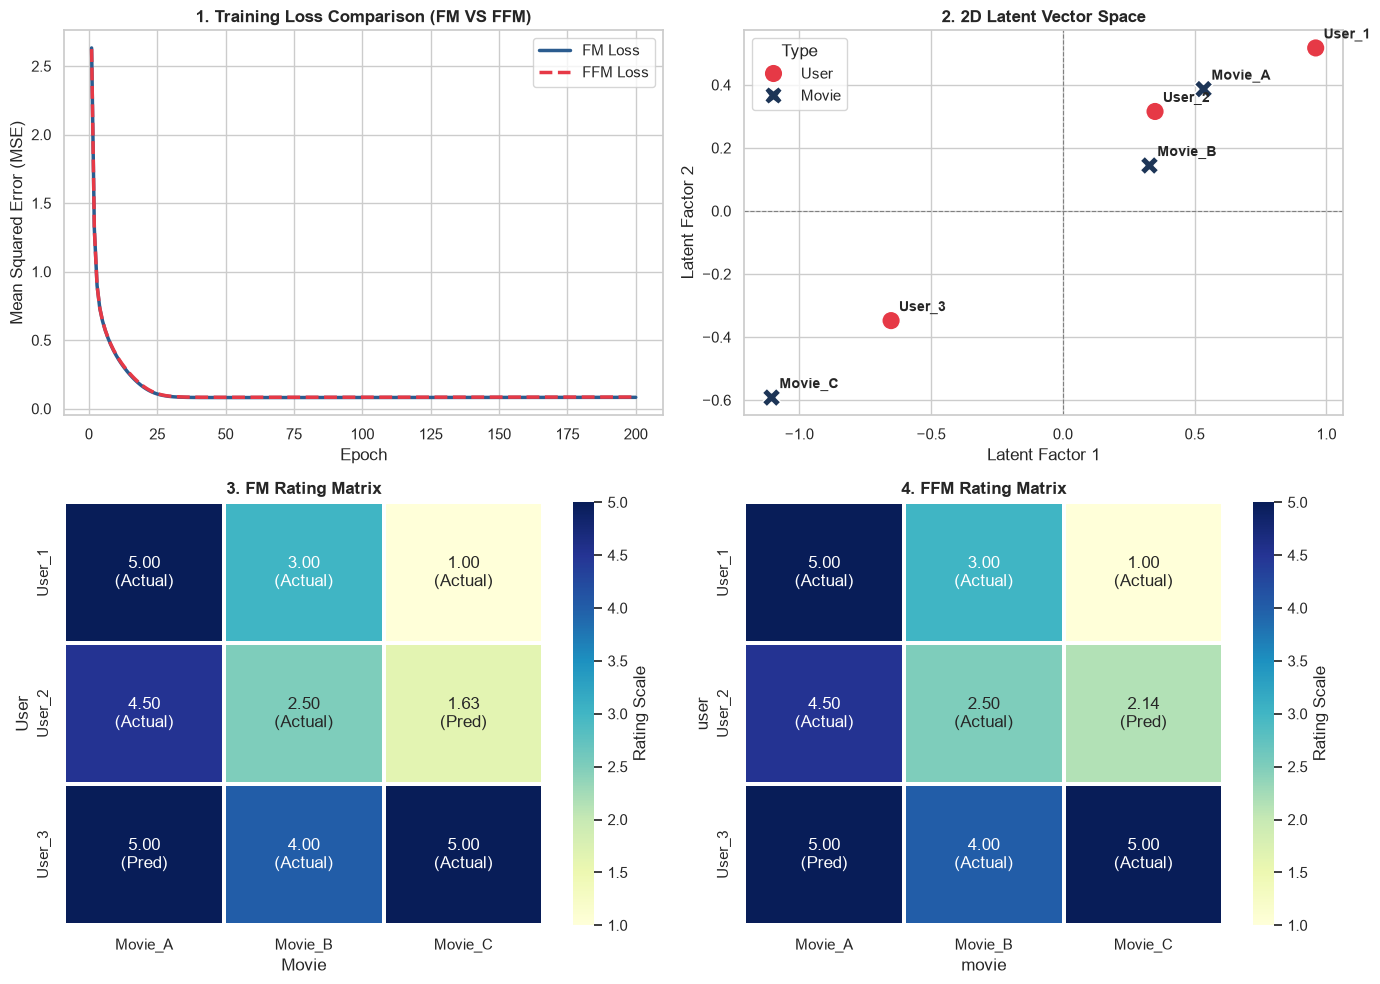

In [12]:
# Atur tata letak mosaic 2x2:
# Baris atas: Perbandingan Loss (ax1) & Peta Vektor Laten FM (ax2)
# Baris bawah: Matriks Rating FM (ax3) & Matriks Rating FFM (ax4)
fig, axes = plt.subplot_mosaic(
  [["ax1", "ax2"], ["ax3", "ax4"]],
  figsize=(14, 10),
  gridspec_kw={"height_ratios": [1, 1.1]},
)

ax1 = axes["ax1"]
ax2 = axes["ax2"]
ax3 = axes["ax3"]
ax4 = axes["ax4"]

# ==============================================================================
# 1. GRAFIK PERBANDINGAN KURVA PENURUNAN ERROR (FM VS FFM)
# ==============================================================================
# Memplot nilai Mean Squared Error (MSE) kedua model untuk membandingkan kecepatan konvergensi
sns.lineplot(
  x=range(1, len(fm.lossHistory) + 1),
  y=fm.lossHistory,
  ax=ax1,
  color='#2b5c8f',
  linewidth=2.5,
  label='FM Loss',
)
sns.lineplot(
  x=range(1, len(ffm.lossHistory) + 1),
  y=ffm.lossHistory,
  ax=ax1,
  color='#e63946',
  linewidth=2.5,
  linestyle='--',
  label='FFM Loss',
)
ax1.set_title('1. Training Loss Comparison (FM VS FFM)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Mean Squared Error (MSE)')
ax1.legend()

# ==============================================================================
# 2. GRAFIK PETA VEKTOR LATEN 2D (LATENT SPACE EMBEDDING)
# ==============================================================================
# Mengambil daftar nama fitur hasil One-Hot Encoding dan nilai matriks vektor laten (fm.v)
featureNames = dfEncoded.columns.tolist()
latentDf = pd.DataFrame(fm.v, columns=['Latent Factor 1', 'Latent Factor 2'])
latentDf['Feature'] = featureNames

# Mengelompokkan setiap fitur apakah termasuk kategori 'User' atau 'Movie'
latentDf['Type'] = ['User' if 'user' in name else 'Movie' for name in featureNames]

# Memplot posisi setiap User dan Movie ke dalam koordinat 2 dimensi
sns.scatterplot(
  data=latentDf,
  x='Latent Factor 1',
  y='Latent Factor 2',
  hue='Type',
  style='Type',
  s=180,
  ax=ax2,
  palette={'User': '#e63946', 'Movie': '#1d3557'},
)

# Menambahkan label nama bersih (tanpa awalan 'user_' atau 'movie_') di samping tiap titik
for _, row in latentDf.iterrows():
  labelClean = row['Feature'].replace('user_', '').replace('movie_', '')
  ax2.text(
    row['Latent Factor 1'] + 0.03,
    row['Latent Factor 2'] + 0.03,
    labelClean,
    fontsize=10,
    fontweight='bold',
  )

ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax2.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax2.set_title('2. 2D Latent Vector Space', fontsize=12, fontweight='bold')

# ==============================================================================
# 3. GRAFIK HEATMAP MATRIKS RATING (FM VS FFM)
# ==============================================================================
def plotRatingHeatmap(predsList, targetAx, titleText):
  """
    Menggabungkan data aktual dan hasil prediksi model menjadi matriks heatmap.
  """
  # Menyiapkan salinan data baru dan menambahkan hasil prediksi model 
  dfPreds = dfNew.copy()
  dfPreds['rating'] = predsList
  dfPreds['status']  = 'Predicted'

  dfOrig = df.copy()
  dfOrig['status'] = 'Actual'

  dfAll = pd.concat([dfOrig, dfPreds], ignore_index=True)
  ratingMatrix = dfAll.pivot(index='user', columns='movie', values='rating')

  annotMatrix = pd.DataFrame('', index=ratingMatrix.index, columns=ratingMatrix.columns)
  for _, row in dfAll.iterrows():
    tag = '(Pred)' if row['status'] == 'Predicted' else '(Actual)'
    annotMatrix.loc[row['user'], row['movie']] = f'{row['rating']:.2f}\n{tag}'
  
  sns.heatmap(
    ratingMatrix,
    annot=annotMatrix,
    fmt='',
    cmap='YlGnBu',
    vmin=1.0,
    vmax=5.0,
    cbar_kws={'label': 'Rating Scale'},
    ax=targetAx,
    linewidths=1.5,
  )

  # targetAx.set_title('3. Complete Rating Matrix (Actual vs Predicted)', fontsize=12, fontweight='bold')
  targetAx.set_title(titleText, fontsize=12, fontweight='bold')
  ax3.set_xlabel('Movie')
  ax3.set_ylabel('User')

plotRatingHeatmap(dfNew['predictedRatingFM'], ax3, '3. FM Rating Matrix')
plotRatingHeatmap(dfNew['predictedRatingFFM'], ax4, '4. FFM Rating Matrix')

plt.tight_layout()
plt.show()